# Optimización y comparación temporal de modelos para predicción de mora

Este cuaderno ajusta cinco algoritmos previamente comparados: regresión logística, árbol, Random Forest, Extra Trees e HistGradientBoosting. Todos usan los mismos cinco folds temporales y los mismos predictores. La selección se hace por **F1 macro medio**, con desviación entre folds como indicador de estabilidad. Los tres meses finales quedan reservados para prueba y no intervienen en la búsqueda.

Los datos son sintéticos. Los resultados son demostrativos y requieren auditar la disponibilidad temporal de variables históricas antes de una interpretación operacional.

## Resultados ejecutados

Se probaron **8 configuraciones exploratorias más la configuración previa de cada modelo**, con **5 folds temporales por configuración**. El criterio de selección fue el F1 macro medio en validación; la prueba final quedó fuera de la búsqueda.

| Modelo | F1 macro CV | Desv. estándar | F1 macro test futuro | Accuracy test |
|---|---:|---:|---:|---:|
| HistGradientBoosting | 0,9759 | 0,0068 | **0,9833** | **0,9892** |
| Random Forest | 0,9729 | 0,0051 | 0,9795 | 0,9870 |
| Extra Trees | 0,9741 | 0,0033 | 0,9762 | 0,9855 |
| Árbol de decisión | 0,9590 | 0,0054 | 0,9677 | 0,9791 |
| Regresión logística | 0,9559 | 0,0045 | 0,9631 | 0,9769 |

**Ganador por validación temporal:** HistGradientBoosting, con `max_iter=150`, `max_leaf_nodes=31`, `learning_rate=0.08`, `l2_regularization=1.0` y `min_samples_leaf=20`. Su configuración ganadora coincide con la anterior; la búsqueda no encontró una mejora temporal fiable. Extra Trees mejoró su F1 macro CV en **0,63 puntos porcentuales** frente a la referencia anterior. Random Forest quedó prácticamente igual. En el test, HistGradientBoosting superó a Random Forest por **0,00380** de F1 macro; el ganador se eligió únicamente con validación temporal y no se ajustó con el test.

El modelo ganador logró **balanced accuracy 0,9837**, **F1 macro 0,9833** y **log loss 0,0427** en los tres meses futuros de prueba (2.685 filas). Estos datos son sintéticos: las cifras no representan desempeño real de una cartera.

## 1. Instalar e importar bibliotecas

In [ ]:
# Se instala scikit-learn únicamente si el entorno no lo tiene disponible.
%pip -q install scikit-learn pandas numpy matplotlib seaborn joblib

# Se importan las herramientas de cálculo y manejo de datos.
import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Se importan las herramientas para preprocesar datos y construir modelos.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, ParameterSampler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score,
    recall_score, log_loss, confusion_matrix, classification_report
)
from IPython.display import display
import joblib

# Se configura una semilla fija para que el muestreo de hiperparámetros sea reproducible.
SEMILLA = 42
np.random.seed(SEMILLA)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120


## 2. Cargar y validar el CSV maestro

In [ ]:
# Se solicita el archivo CSV maestro al abrir el notebook en Google Colab.
try:
    from google.colab import files
    archivos_subidos = files.upload()
    ruta_csv = next((nombre for nombre in archivos_subidos if nombre.lower().endswith(".csv")), None)
except ImportError:
    # Se usa esta ruta cuando el notebook se ejecuta localmente junto al CSV.
    ruta_csv = "dataset_mora_completo_para_modelo_temporal.csv"

# Se comprueba que se haya seleccionado el CSV correcto antes de continuar.
if ruta_csv is None or not os.path.exists(ruta_csv):
    raise FileNotFoundError("Sube dataset_mora_completo_para_modelo_temporal.csv y vuelve a ejecutar esta celda.")

# Se carga el conjunto con la fecha convertida al tipo calendario.
datos = pd.read_csv(ruta_csv, parse_dates=["fecha_reporte"])

# Se comprueba que estén presentes fecha, objetivo y campos esperados.
assert {"fecha_reporte", "mora"}.issubset(datos.columns), "El CSV requiere fecha_reporte y mora."
datos = datos.sort_values("fecha_reporte").reset_index(drop=True)
meses = np.array(sorted(datos["fecha_reporte"].dt.to_period("M").unique()))
print(f"Filas: {len(datos):,}; meses: {len(meses)}; periodo: {meses[0]} a {meses[-1]}")
display(datos.head(3))


## 3. Definir particiones y folds temporales
Se conservan los cortes anteriores: 18 meses de desarrollo, 3 de calibración y 3 de prueba futura. La calibración se mantiene fuera del ajuste y el test final permanece intacto hasta la evaluación final. Los folds se construyen por meses, no por filas aleatorias.

In [ ]:
# Se confirma que existan los 24 meses del diseño temporal previo.
assert len(meses) >= 24, "El diseño temporal requiere al menos 24 meses."

# Se asignan los primeros 18 meses al desarrollo del modelo.
meses_desarrollo = meses[:18]

# Se dejan tres meses intermedios reservados para calibración.
meses_calibracion = meses[18:21]

# Se reservan los últimos tres meses como test futuro final.
meses_test = meses[21:24]

# Se identifican las variables que no deben entrar como predictores.
columnas_excluidas = ["ID", "fecha_reporte", "atraso", "mora"]
variables = [col for col in datos.columns if col not in columnas_excluidas]
objetivo = "mora"

# Se crea una partición de desarrollo por mes para alimentar cinco folds expansivos.
mes_registro = datos["fecha_reporte"].dt.to_period("M")
mascara_desarrollo = mes_registro.isin(meses_desarrollo)
indices_desarrollo = np.flatnonzero(mascara_desarrollo.to_numpy())
y_desarrollo = datos.loc[mascara_desarrollo, objetivo].astype(str).reset_index(drop=True)

# Se generan cinco folds, con dos meses consecutivos por validación.
separador_temporal = TimeSeriesSplit(n_splits=5, test_size=2)
folds = []
for indices_train_local, indices_val_local in separador_temporal.split(meses_desarrollo):
    # Se convierten las ventanas de meses en los índices de filas correspondientes.
    meses_train_fold = meses_desarrollo[indices_train_local]
    meses_val_fold = meses_desarrollo[indices_val_local]
    mask_train_local = mes_registro.iloc[indices_desarrollo].isin(meses_train_fold).to_numpy()
    mask_val_local = mes_registro.iloc[indices_desarrollo].isin(meses_val_fold).to_numpy()
    indices_train_filas = np.flatnonzero(mask_train_local)
    indices_val_filas = np.flatnonzero(mask_val_local)
    folds.append((indices_train_filas, indices_val_filas))

# Se muestran los intervalos temporales de cada fold para verificar el orden.
resumen_folds = []
for numero_fold, (idx_train, idx_val) in enumerate(folds, start=1):
    resumen_folds.append({
        "fold": numero_fold,
        "mes_inicio_train": str(meses_desarrollo[0]),
        "mes_fin_train": str(mes_registro.iloc[indices_desarrollo[idx_train]].max()),
        "mes_inicio_validacion": str(mes_registro.iloc[indices_desarrollo[idx_val]].min()),
        "mes_fin_validacion": str(mes_registro.iloc[indices_desarrollo[idx_val]].max()),
        "filas_train": len(idx_train),
        "filas_validacion": len(idx_val)
    })
display(pd.DataFrame(resumen_folds))


## 4. Preparar el preprocesamiento sin fuga entre folds
La imputación, el escalado y la codificación se ajustan de nuevo dentro de cada fold usando únicamente el bloque de entrenamiento. El ajuste de pesos de HistGradientBoosting también usa solo las etiquetas del fold de entrenamiento.

In [ ]:
# Se obtienen los tipos de columna usando los predictores de la partición de desarrollo.
X_desarrollo = datos.loc[mascara_desarrollo, variables].reset_index(drop=True)
columnas_numericas = X_desarrollo.select_dtypes(include=np.number).columns.tolist()
columnas_categoricas = [col for col in variables if col not in columnas_numericas]

# Se define una función que crea un preprocesador nuevo para cada ajuste.
def crear_preprocesador():
    # Se imputan valores numéricos con la mediana y luego se estandarizan.
    transformacion_numerica = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ])
    # Se imputan categorías con el valor más frecuente y se convierten a indicadores.
    transformacion_categorica = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    # Se aplican transformaciones según el tipo de cada predictor.
    return ColumnTransformer([
        ("numericas", transformacion_numerica, columnas_numericas),
        ("categoricas", transformacion_categorica, columnas_categoricas)
    ], sparse_threshold=0)

# Se declara un muestreo compacto pero diverso de hiperparámetros por algoritmo.
espacios_parametros = {
    "Regresión logística": [
        {"C": valor, "solver": "lbfgs", "max_iter": 3000, "class_weight": "balanced"}
        for valor in [0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]
    ],
    "Árbol de decisión": [
        {"max_depth": profundidad, "min_samples_leaf": hoja, "min_samples_split": division, "class_weight": "balanced"}
        for profundidad in [6, 10, 14, 20, None]
        for hoja in [4, 8, 16]
        for division in [2, 10]
    ],
    "Random Forest": [
        {"n_estimators": arboles, "max_depth": profundidad, "min_samples_leaf": hoja, "max_features": rasgos, "class_weight": peso, "n_jobs": -1}
        for arboles in [120, 200]
        for profundidad in [None, 14, 24]
        for hoja in [1, 2, 4]
        for rasgos in ["sqrt", 0.6]
        for peso in ["balanced_subsample", "balanced"]
    ],
    "Extra Trees": [
        {"n_estimators": arboles, "max_depth": profundidad, "min_samples_leaf": hoja, "max_features": rasgos, "class_weight": peso, "n_jobs": -1}
        for arboles in [120, 200]
        for profundidad in [None, 14, 24]
        for hoja in [1, 2, 4]
        for rasgos in ["sqrt", 0.6]
        for peso in ["balanced", "balanced_subsample"]
    ],
    "HistGradientBoosting": [
        {"max_iter": iteraciones, "max_leaf_nodes": hojas, "learning_rate": tasa, "l2_regularization": regularizacion, "min_samples_leaf": minimo, "early_stopping": False}
        for iteraciones in [100, 150, 220]
        for hojas in [15, 31, 63]
        for tasa in [0.04, 0.08, 0.12]
        for regularizacion in [0.0, 1.0, 5.0]
        for minimo in [10, 20, 30]
    ]
}

# Se fija el número de configuraciones aleatorias por algoritmo, además de su configuración previa.
NUM_CONFIGURACIONES = 8

# Se agrega la configuración previa de cada algoritmo como referencia dentro de la búsqueda.
configuraciones_referencia = {
    "Regresión logística": {"C": 1.0, "solver": "lbfgs", "max_iter": 2500, "class_weight": "balanced"},
    "Árbol de decisión": {"max_depth": 14, "min_samples_leaf": 8, "min_samples_split": 2, "class_weight": "balanced"},
    "Random Forest": {"n_estimators": 250, "max_depth": None, "min_samples_leaf": 2, "max_features": "sqrt", "class_weight": "balanced_subsample", "n_jobs": -1},
    "Extra Trees": {"n_estimators": 250, "max_depth": None, "min_samples_leaf": 2, "max_features": "sqrt", "class_weight": "balanced", "n_jobs": -1},
    "HistGradientBoosting": {"max_iter": 150, "max_leaf_nodes": 31, "learning_rate": 0.08, "l2_regularization": 1.0, "min_samples_leaf": 20, "early_stopping": False}
}

# Se crea una fábrica que genera el clasificador correcto con cada combinación.
def crear_estimador(nombre, parametros):
    if nombre == "Regresión logística":
        return LogisticRegression(random_state=SEMILLA, **parametros)
    if nombre == "Árbol de decisión":
        return DecisionTreeClassifier(random_state=SEMILLA, **parametros)
    if nombre == "Random Forest":
        return RandomForestClassifier(random_state=SEMILLA, **parametros)
    if nombre == "Extra Trees":
        return ExtraTreesClassifier(random_state=SEMILLA, **parametros)
    return HistGradientBoostingClassifier(random_state=SEMILLA, **parametros)

# Se crea un pipeline para que el preprocesamiento ocurra dentro de cada fold.
def crear_pipeline(nombre, parametros):
    return Pipeline([
        ("preprocesador", crear_preprocesador()),
        ("modelo", crear_estimador(nombre, parametros))
    ])


## 5. Buscar hiperparámetros con validación temporal
Cada combinación se evalúa en los cinco folds. Se selecciona la combinación con mayor F1 macro medio; la dispersión entre folds se conserva como advertencia de estabilidad. No se utiliza el conjunto final de prueba para elegir parámetros.

In [ ]:
# Se prepara una lista para guardar cada resultado por modelo, configuración y fold.
resultados_busqueda = []
configuraciones_ganadoras = {}
inicio_busqueda = time.perf_counter()

# Se recorre cada algoritmo con su espacio de hiperparámetros.
for nombre_modelo, espacio in espacios_parametros.items():
    # Se toma una muestra reproducible de configuraciones del espacio declarado.
    indices_muestreados = np.random.default_rng(SEMILLA).choice(
        len(espacio), size=min(NUM_CONFIGURACIONES, len(espacio)), replace=False
    )
    lista_configuraciones = [espacio[indice] for indice in indices_muestreados]
    # Se incluye la configuración anterior para asegurar una comparación directa.
    parametros_referencia = configuraciones_referencia[nombre_modelo]
    if parametros_referencia not in lista_configuraciones:
        lista_configuraciones.append(parametros_referencia)
    # Se evalúa cada combinación con las mismas ventanas temporales.
    for numero_configuracion, parametros in enumerate(lista_configuraciones, start=1):
        print(f"{nombre_modelo}: configuración {numero_configuracion}/{len(lista_configuraciones)}")
        # Se inicia una colección de métricas para resumir esta configuración.
        metricas_configuracion = []
        # Se ajusta el pipeline desde cero en cada fold.
        for numero_fold, (idx_train, idx_val) in enumerate(folds, start=1):
            # Se separan los predictores y etiquetas locales del fold.
            X_train_fold = X_desarrollo.iloc[idx_train]
            y_train_fold = y_desarrollo.iloc[idx_train]
            X_val_fold = X_desarrollo.iloc[idx_val]
            y_val_fold = y_desarrollo.iloc[idx_val]
            # Se crea y ajusta el pipeline con la configuración candidata.
            pipeline_candidato = crear_pipeline(nombre_modelo, parametros)
            # Se calcula ponderación solo para HistGradientBoosting y solo con train del fold.
            if nombre_modelo == "HistGradientBoosting":
                pesos_fold = compute_sample_weight(class_weight="balanced", y=y_train_fold)
                pipeline_candidato.fit(X_train_fold, y_train_fold, modelo__sample_weight=pesos_fold)
            else:
                pipeline_candidato.fit(X_train_fold, y_train_fold)
            # Se genera la predicción de la ventana futura del fold.
            prediccion_fold = pipeline_candidato.predict(X_val_fold)
            # Se registran las métricas principales de la validación temporal.
            metricas_configuracion.append({
                "f1_macro": f1_score(y_val_fold, prediccion_fold, average="macro", zero_division=0),
                "balanced_accuracy": balanced_accuracy_score(y_val_fold, prediccion_fold),
                "accuracy": accuracy_score(y_val_fold, prediccion_fold)
            })
            # Se guarda la combinación y la métrica del fold para auditoría.
            resultados_busqueda.append({
                "modelo": nombre_modelo,
                "configuracion": numero_configuracion,
                "fold": numero_fold,
                "f1_macro": metricas_configuracion[-1]["f1_macro"],
                "balanced_accuracy": metricas_configuracion[-1]["balanced_accuracy"],
                "accuracy": metricas_configuracion[-1]["accuracy"],
                "hiperparametros": json.dumps(parametros, ensure_ascii=False, sort_keys=True)
            })
        # Se promedian las métricas temporales para esta configuración.
        f1_medio_configuracion = np.mean([m["f1_macro"] for m in metricas_configuracion])
        f1_sd_configuracion = np.std([m["f1_macro"] for m in metricas_configuracion], ddof=1)
        # Se retiene como ganador del algoritmo el F1 macro medio más alto.
        if nombre_modelo not in configuraciones_ganadoras or f1_medio_configuracion > configuraciones_ganadoras[nombre_modelo]["f1_macro_media"]:
            configuraciones_ganadoras[nombre_modelo] = {
                "parametros": parametros,
                "f1_macro_media": f1_medio_configuracion,
                "f1_macro_sd": f1_sd_configuracion,
                "metricas_folds": metricas_configuracion
            }

# Se informa cuánto tiempo consumió la búsqueda completa.
tiempo_busqueda = time.perf_counter() - inicio_busqueda
print(f"Búsqueda completada en {tiempo_busqueda/60:.1f} minutos.")


## 6. Comparar modelos optimizados
La tabla ordena modelos por F1 macro promedio en los folds temporales. También muestra desviación, balanced accuracy, accuracy, parámetros seleccionados y comparación con los resultados anteriores sin optimizar.

modelo,f1_macro_media_cv,f1_macro_sd_cv,f1_macro_previo_cv,mejora_vs_previo_pp,f1_macro_test,accuracy_test
HistGradientBoosting,0.9759,0.0068,0.9759,-0.0000,0.9833,0.9892
Extra Trees,0.9741,0.0033,0.9678,0.6344,0.9762,0.9855
Random Forest,0.9729,0.0051,0.9727,0.0121,0.9795,0.9870
Árbol de decisión,0.9590,0.0054,0.9561,0.2847,0.9677,0.9791
Regresión logística,0.9559,0.0045,0.9534,0.2547,0.9631,0.9769


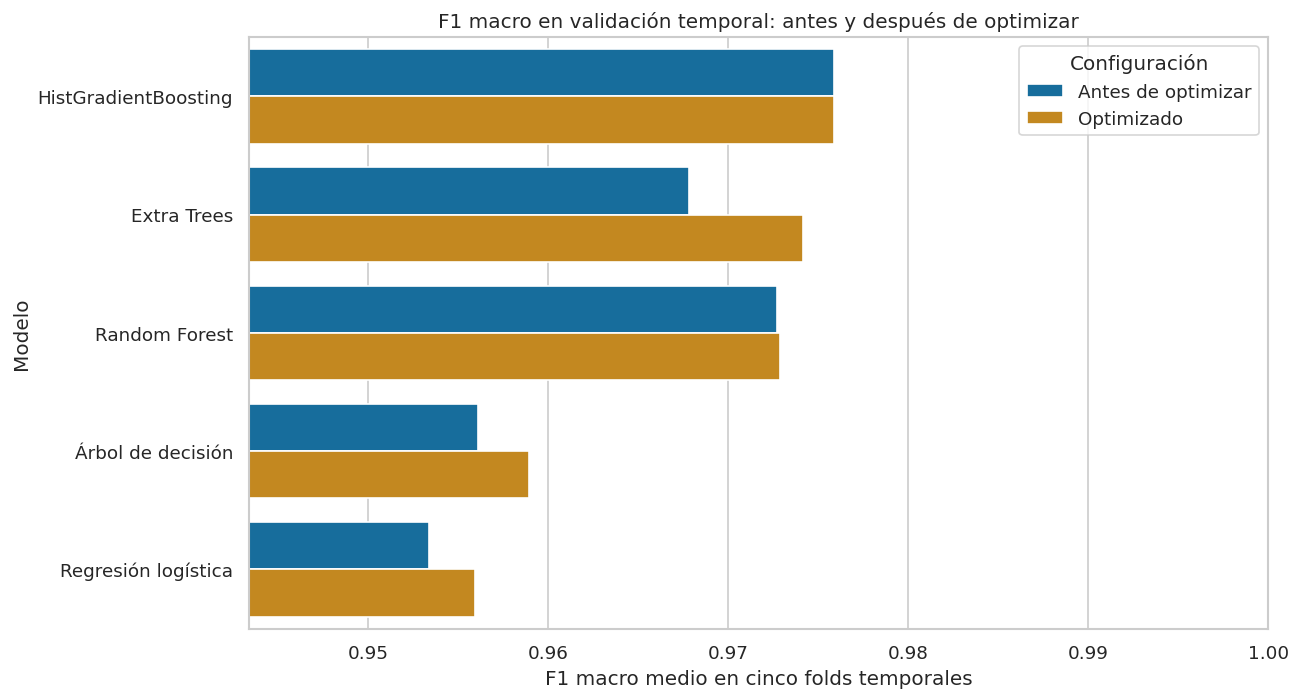

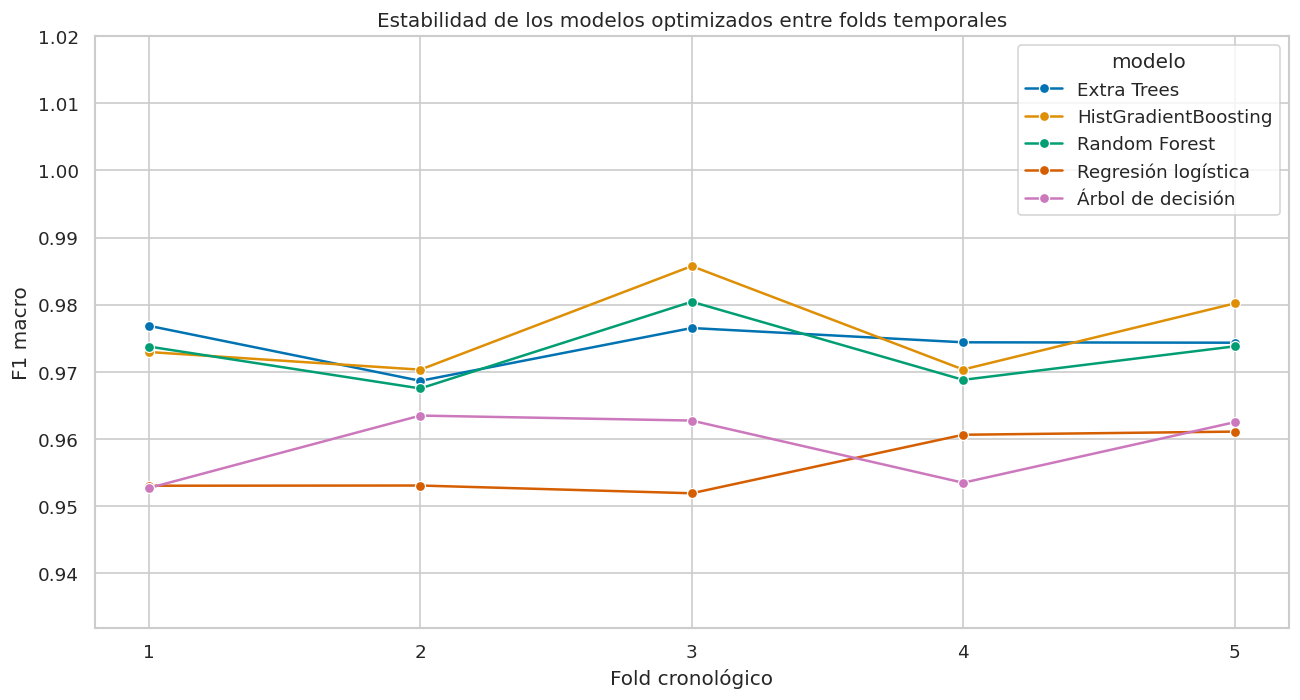

In [14]:
# Se recuperan los registros de la mejor configuración de cada algoritmo.
resumen_modelos = []
for nombre, resultado in configuraciones_ganadoras.items():
    metricas = resultado["metricas_folds"]
    resumen_modelos.append({
        "modelo": nombre,
        "f1_macro_media_cv": np.mean([m["f1_macro"] for m in metricas]),
        "f1_macro_sd_cv": np.std([m["f1_macro"] for m in metricas], ddof=1),
        "balanced_accuracy_media_cv": np.mean([m["balanced_accuracy"] for m in metricas]),
        "accuracy_media_cv": np.mean([m["accuracy"] for m in metricas]),
        "hiperparametros_optimos": json.dumps(resultado["parametros"], ensure_ascii=False, sort_keys=True)
    })
comparacion_optimizada = pd.DataFrame(resumen_modelos).sort_values("f1_macro_media_cv", ascending=False).reset_index(drop=True)

# Se incorpora la referencia de validación cruzada sin ajuste realizada anteriormente.
f1_previo = {
    "HistGradientBoosting": 0.9759030978,
    "Random Forest": 0.9727369153,
    "Extra Trees": 0.9678037443,
    "Regresión logística": 0.9533860795,
    "Árbol de decisión": 0.9561174547
}
comparacion_optimizada["f1_macro_previo_cv"] = comparacion_optimizada["modelo"].map(f1_previo)
comparacion_optimizada["mejora_vs_previo_pp"] = 100 * (comparacion_optimizada["f1_macro_media_cv"] - comparacion_optimizada["f1_macro_previo_cv"])
display(comparacion_optimizada.round(4))

# Se grafican los promedios F1 de la referencia previa y de cada modelo optimizado.
comparacion_grafico = comparacion_optimizada.melt(
    id_vars="modelo",
    value_vars=["f1_macro_previo_cv", "f1_macro_media_cv"],
    var_name="version",
    value_name="f1_macro"
)
comparacion_grafico["version"] = comparacion_grafico["version"].map({
    "f1_macro_previo_cv": "Antes de optimizar",
    "f1_macro_media_cv": "Optimizado"
})
plt.figure(figsize=(11, 6))
sns.barplot(data=comparacion_grafico, x="f1_macro", y="modelo", hue="version")
plt.title("F1 macro en validación temporal: antes y después de optimizar")
plt.xlabel("F1 macro medio en cinco folds temporales")
plt.ylabel("Modelo")
plt.xlim(max(0.0, comparacion_grafico["f1_macro"].min() - 0.01), 1.0)
plt.legend(title="Configuración")
plt.tight_layout()
plt.show()

# Se grafica el F1 macro de cada fold para mostrar estabilidad temporal.
filas_folds_ganadores = []
for nombre, resultado in configuraciones_ganadoras.items():
    for numero_fold, metrica in enumerate(resultado["metricas_folds"], start=1):
        filas_folds_ganadores.append({"modelo": nombre, "fold": numero_fold, "f1_macro": metrica["f1_macro"]})
f1_por_fold = pd.DataFrame(filas_folds_ganadores)
plt.figure(figsize=(11, 6))
sns.lineplot(data=f1_por_fold, x="fold", y="f1_macro", hue="modelo", marker="o")
plt.title("Estabilidad de los modelos optimizados entre folds temporales")
plt.xlabel("Fold cronológico")
plt.ylabel("F1 macro")
plt.xticks(sorted(f1_por_fold["fold"].unique()))
plt.ylim(max(0.0, f1_por_fold["f1_macro"].min() - 0.02), 1.02)
plt.tight_layout()
plt.show()


## 7. Entrenar el ganador y evaluar una sola vez en el test futuro
El ganador se determina exclusivamente por los folds. El modelo final se entrena en los primeros 18 meses. Se evalúa una sola vez en junio–agosto de 2026 para evitar escoger un modelo mirando el test.

In [16]:
# Se define como ganador el algoritmo con mayor F1 macro medio en la validación temporal.
nombre_ganador = comparacion_optimizada.loc[0, "modelo"]
parametros_ganadores = configuraciones_ganadoras[nombre_ganador]["parametros"]  # Conserva la configuración seleccionada para exportar el modelo.
print("Ganador seleccionado exclusivamente con validación temporal:", nombre_ganador)

# Se separan los datos históricos y el conjunto futuro reservado para evaluación final.
X_train_final = datos.loc[mes_registro.isin(meses_desarrollo), variables]
y_train_final = datos.loc[mes_registro.isin(meses_desarrollo), objetivo].astype(str)
X_test = datos.loc[mes_registro.isin(meses_test), variables]
y_test = datos.loc[mes_registro.isin(meses_test), objetivo].astype(str)

# Se preparan colecciones para guardar métricas, pipelines y predicciones de cada finalista.
metricas_test_lista = []
modelos_test = {}
predicciones_por_modelo = {}
probabilidades_por_modelo = {}

# Se ajusta cada modelo con sus mejores hiperparámetros y se prueba sin reajustar.
for nombre_modelo in comparacion_optimizada["modelo"]:
    # Se recuperan los parámetros seleccionados por los folds temporales de este modelo.
    parametros = configuraciones_ganadoras[nombre_modelo]["parametros"]
    # Se crea un pipeline nuevo para entrenar este finalista desde cero.
    pipeline_finalista = crear_pipeline(nombre_modelo, parametros)
    # Se ponderan las clases de HistGradientBoosting con las etiquetas del train final.
    if nombre_modelo == "HistGradientBoosting":
        pesos_finales = compute_sample_weight(class_weight="balanced", y=y_train_final)
        pipeline_finalista.fit(X_train_final, y_train_final, modelo__sample_weight=pesos_finales)
    else:
        pipeline_finalista.fit(X_train_final, y_train_final)
    # Se calculan clases y probabilidades para los meses finales de prueba.
    prediccion_modelo = pipeline_finalista.predict(X_test)
    probabilidad_modelo = pipeline_finalista.predict_proba(X_test)
    clases_modelo = pipeline_finalista.named_steps["modelo"].classes_
    # Se conservan modelos y predicciones para comparación y exportación.
    modelos_test[nombre_modelo] = pipeline_finalista
    predicciones_por_modelo[nombre_modelo] = prediccion_modelo
    probabilidades_por_modelo[nombre_modelo] = probabilidad_modelo
    # Se calcula el mismo conjunto de métricas para comparar a todos en el test.
    metricas_test_lista.append({
        "modelo": nombre_modelo,
        "accuracy_test": accuracy_score(y_test, prediccion_modelo),
        "balanced_accuracy_test": balanced_accuracy_score(y_test, prediccion_modelo),
        "precision_macro_test": precision_score(y_test, prediccion_modelo, average="macro", zero_division=0),
        "recall_macro_test": recall_score(y_test, prediccion_modelo, average="macro", zero_division=0),
        "f1_macro_test": f1_score(y_test, prediccion_modelo, average="macro", zero_division=0),
        "f1_weighted_test": f1_score(y_test, prediccion_modelo, average="weighted", zero_division=0),
        "log_loss_test": log_loss(y_test, probabilidad_modelo, labels=clases_modelo)
    })

# Se organiza la evaluación final y se une a la comparación de validación cruzada.
metricas_test = pd.DataFrame(metricas_test_lista)
comparacion_optimizada = comparacion_optimizada.merge(metricas_test, on="modelo", how="left")
comparacion_optimizada = comparacion_optimizada.sort_values("f1_macro_media_cv", ascending=False).reset_index(drop=True)
print("Comparación final: los valores de test son descriptivos y no cambian la selección.")
display(comparacion_optimizada[[
    "modelo", "f1_macro_media_cv", "f1_macro_sd_cv", "f1_macro_previo_cv",
    "mejora_vs_previo_pp", "f1_macro_test", "balanced_accuracy_test", "accuracy_test"
]].round(4))

# Se recuperan las predicciones del modelo seleccionado usando solo validación temporal.
modelo_final = modelos_test[nombre_ganador]
predicciones_test = predicciones_por_modelo[nombre_ganador]
probabilidades_test = probabilidades_por_modelo[nombre_ganador]
clases = modelo_final.named_steps["modelo"].classes_

# Se muestra el reporte por clase del ganador seleccionado antes de consultar el test.
print("Reporte del modelo ganador en el test futuro:")
print(classification_report(y_test, predicciones_test, labels=clases, zero_division=0))


modelo,accuracy_test,balanced_accuracy_test,precision_macro_test,recall_macro_test,f1_macro_test,f1_weighted_test,log_loss_test
HistGradientBoosting,0.9892,0.9837,0.9830,0.9837,0.9833,0.9892,0.0427
Extra Trees,0.9855,0.9774,0.9751,0.9774,0.9762,0.9854,0.0448
Random Forest,0.9870,0.9801,0.9791,0.9801,0.9795,0.9869,0.0550
Árbol de decisión,0.9791,0.9714,0.9644,0.9714,0.9677,0.9792,0.4451
Regresión logística,0.9769,0.9676,0.9590,0.9676,0.9631,0.9772,0.0723


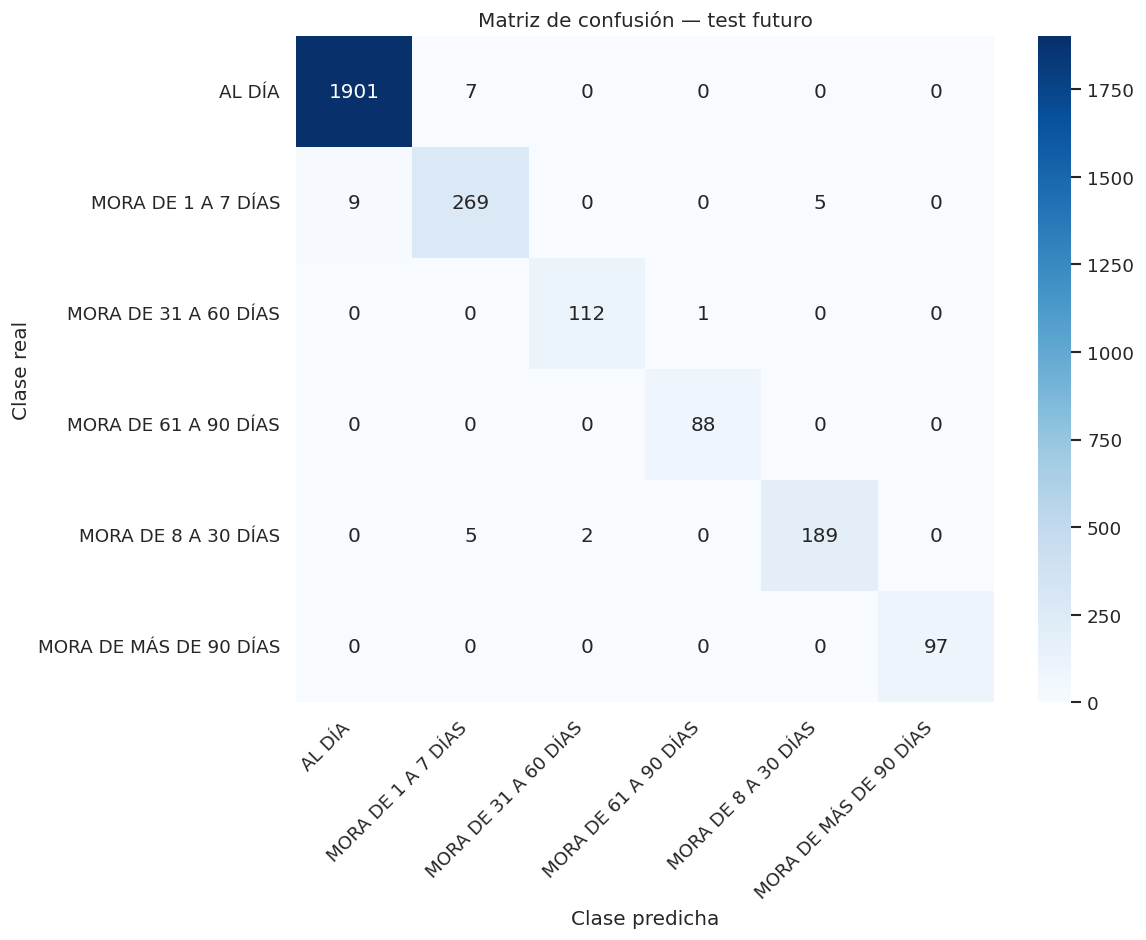

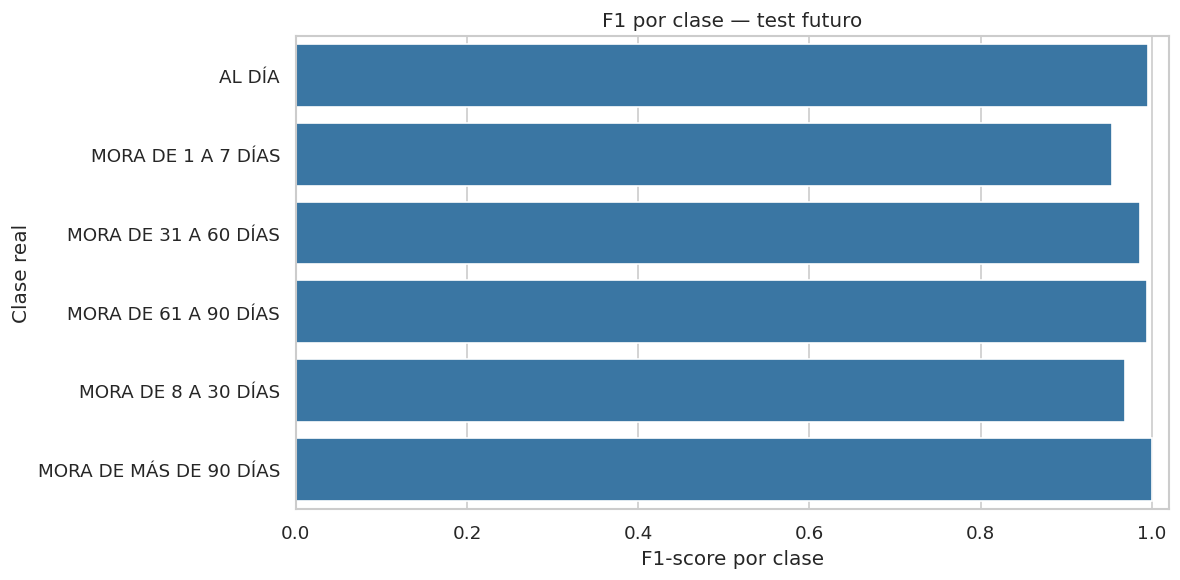

In [17]:
# Se calculan la matriz de confusión y el F1 individual de cada clase.
matriz_confusion = confusion_matrix(y_test, predicciones_test, labels=clases)
f1_por_clase = pd.DataFrame({
    "clase": clases,
    "f1": [f1_score(y_test, predicciones_test, labels=[clase], average="micro", zero_division=0) for clase in clases],
    "soporte": [(y_test == clase).sum() for clase in clases]
})

# Se grafica la matriz de confusión para revisar aciertos y errores por categoría.
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_confusion, annot=True, fmt="d", cmap="Blues", xticklabels=clases, yticklabels=clases)
plt.title("Matriz de confusión — test futuro")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Se grafica el F1 por categoría para visualizar clases de menor rendimiento.
plt.figure(figsize=(10, 5))
sns.barplot(data=f1_por_clase, x="f1", y="clase", color="#2878B5")
plt.title("F1 por clase — test futuro")
plt.xlabel("F1-score por clase")
plt.ylabel("Clase real")
plt.xlim(0, 1.02)
plt.tight_layout()
plt.show()


## 8. Guardar resultados y artefactos
Se exportan la comparación optimizada, el detalle de búsqueda, las métricas de test, las predicciones y el pipeline final.

In [ ]:
# Se convierten todos los resultados evaluados en una tabla para auditoría.
detalle_busqueda = pd.DataFrame(resultados_busqueda)

# Se guardan la tabla comparativa y la búsqueda completa en archivos CSV.
comparacion_optimizada.to_csv("comparacion_modelos_optimizada.csv", index=False)
detalle_busqueda.to_csv("detalle_busqueda_temporal.csv", index=False)
metricas_test.to_csv("metricas_test_futuro_modelo_optimizado.csv", index=False)
f1_por_clase.to_csv("f1_por_clase_test_futuro.csv", index=False)

# Se guardan las predicciones, las probabilidades por clase y los meses de partición.
predicciones_export = pd.DataFrame({
    "clase_real": y_test.to_numpy(),
    "clase_predicha": predicciones_test
})
for indice_clase, nombre_clase in enumerate(clases):
    predicciones_export[f"probabilidad_{indice_clase}"] = probabilidades_test[:, indice_clase]
predicciones_export.to_csv("predicciones_test_futuro_modelo_optimizado.csv", index=False)

# Se serializa el pipeline, su nombre y sus hiperparámetros para reutilización.
joblib.dump({
    "pipeline": modelo_final,
    "nombre_modelo": nombre_ganador,
    "hiperparametros": parametros_ganadores,
    "variables": variables,
    "clases": list(clases),
    "meses_train": [str(mes) for mes in meses_desarrollo],
    "meses_calibracion": [str(mes) for mes in meses_calibracion],
    "meses_test": [str(mes) for mes in meses_test]
}, "modelo_mora_ganador_optimizado.joblib")

# Se informa la ruta de los resultados guardados.
print("Archivos generados: comparación, detalle de búsqueda, métricas, predicciones y modelo ganador.")


## Interpretación y límites

- La optimización maximiza F1 macro dentro de los cinco folds temporales; no garantiza que un único modelo sea óptimo para todos los costos de error.
- Los resultados de prueba final se reportan una vez y no se usan para ajustar hiperparámetros.
- La base de datos es sintética, así que las métricas no se deben presentar como resultados reales de cartera.
- Se debe verificar que `mora_max_*`, `atrasos_*`, `score` y las demás variables estuvieran disponibles al momento de la predicción. Si alguna registra información del mismo periodo objetivo o posterior, hay fuga temporal y debe excluirse antes de volver a optimizar.
- La selección por F1 macro reduce el dominio de la clase mayoritaria, pero las decisiones de crédito requieren costos de falsos positivos/falsos negativos, calibración y auditoría por grupos.
- El conjunto intermedio de calibración se conserva; este cuaderno no lo mezcla con entrenamiento ni test.